In [14]:
import pandas as pd

# CSV 파일과 노트북이 같은 폴더에 있으면 파일명만 바로 적어도 됩니다!
df = pd.read_csv('apple_production_shipment.csv')
print(df.head())

      발간월    표     구분    항목        값       하한       상한      원문      단위
0  202012  생산량  2020년  재배면적  31601.0  31601.0  31601.0  31,601      ha
1  202012  생산량  2020년    단수   1430.0   1430.0   1430.0   1,430  kg/10a
2  202012  생산량  2020년   생산량    451.7    451.7    451.7   451.7     천 톤
3  202012  생산량  2019년  재배면적  32954.0  32954.0  32954.0  32,954      ha
4  202012  생산량  2019년    단수   1624.0   1624.0   1624.0   1,624  kg/10a


In [15]:
import pandas as pd

# 1. CSV 파일 불러오기
df = pd.read_csv('apple_production_shipment.csv')

# 2. 데이터 상위 5개 행 확인
print("--- 데이터 상위 5행 ---")
display(df.head())

# 3. 데이터 구조 및 결측치 확인
print("\n--- 데이터 정보 ---")
df.info()

# 4. 수집된 '발간월' 목록 확인 (어떤 달의 데이터가 들어있는지)
print("\n--- 수집된 발간월 목록 ---")
print(df['발간월'].unique())

--- 데이터 상위 5행 ---


,발간월,표,구분,항목,값,하한,상한,원문,단위
0,202012,생산량,2020년,재배면적,31601.0,31601.0,31601.0,"31,601",ha
1,202012,생산량,2020년,단수,1430.0,1430.0,1430.0,"1,430",kg/10a
2,202012,생산량,2020년,생산량,451.7,451.7,451.7,451.7,천 톤
3,202012,생산량,2019년,재배면적,32954.0,32954.0,32954.0,"32,954",ha
4,202012,생산량,2019년,단수,1624.0,1624.0,1624.0,"1,624",kg/10a



--- 데이터 정보 ---
<class 'pandas.DataFrame'>
RangeIndex: 740 entries, 0 to 739
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   발간월     740 non-null    int64  
 1   표       740 non-null    str    
 2   구분      740 non-null    str    
 3   항목      740 non-null    str    
 4   값       740 non-null    float64
 5   하한      740 non-null    float64
 6   상한      740 non-null    float64
 7   원문      740 non-null    str    
 8   단위      740 non-null    str    
dtypes: float64(3), int64(1), str(5)
memory usage: 78.4 KB

--- 수집된 발간월 목록 ---
[202012 202110 202204 202205 202206 202207 202208 202209 202210 202211
 202212 202304 202305 202306 202307 202308 202309 202310 202311 202312
 202404 202411 202412 202504 202505 202506 202507 202508 202509 202510
 202511 202512 202604 202605 202606 202607 202608 202609 202610]


--- 연도별 생산량 요약 ---


,연도,값
0,2020,301.100000
1,2021,285.060000
2,2022,308.980000
3,2023,297.130000
4,2024,272.975000
5,2025,275.493333
6,2026,300.278571


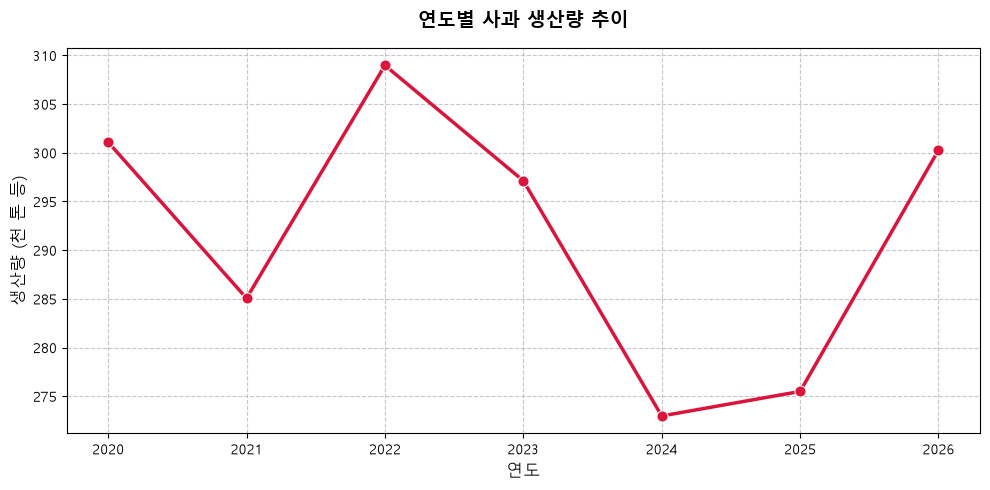

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 폰트 설정 (Windows: Malgun Gothic, Mac: AppleGothic)
plt.rc('font', family='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False

# 1. '표' 또는 '항목'에서 생산량 데이터만 추출
# (예시로 '항목'이 '생산량'인 데이터만 필터링)
df_production = df[df['항목'] == '생산량'].copy()

# 2. 발간월을 기준으로 연도 정보 추출 (예: '202012' -> '2020')
df_production['연도'] = df_production['발간월'].astype(str).str[:4]

# 3. 연도별 생산량 평균(또는 최신 데이터) 집계
yearly_prod = df_production.groupby('연도')['값'].mean().reset_index()

print("--- 연도별 생산량 요약 ---")
display(yearly_prod)

# 4. 시각화 그래프 그리기
plt.figure(figsize=(10, 5))
sns.lineplot(data=yearly_prod, x='연도', y='값', marker='o', color='crimson', linewidth=2.5, markersize=8)

plt.title('연도별 사과 생산량 추이', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('연도', fontsize=12)
plt.ylabel('생산량 (천 톤 등)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

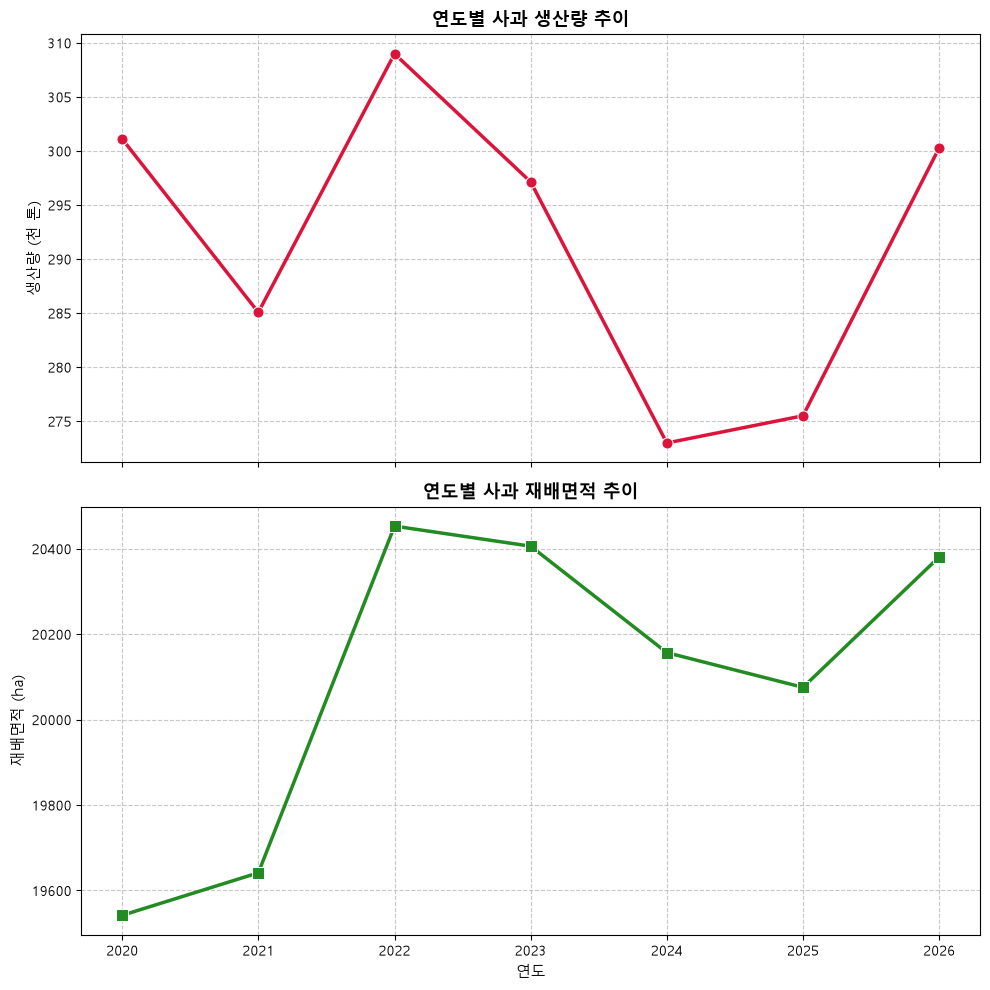

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 폰트 설정
plt.rc('font', family='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False

# 위아래로 2개의 그래프를 그릴 준비 (공유 X축)
fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

# 1. 연도별 생산량 데이터 집계
df_prod = df[df['항목'] == '생산량'].copy()
df_prod['연도'] = df_prod['발간월'].astype(str).str[:4]
yearly_prod = df_prod.groupby('연도')['값'].mean().reset_index()

# 첫 번째 그래프: 생산량
sns.lineplot(data=yearly_prod, x='연도', y='값', ax=axes[0], marker='o', color='crimson', linewidth=2.5, markersize=8)
axes[0].set_title('연도별 사과 생산량 추이', fontsize=13, fontweight='bold')
axes[0].set_ylabel('생산량 (천 톤)', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.7)

# 2. 연도별 재배면적 데이터 집계
df_area = df[df['항목'] == '재배면적'].copy()
df_area['연도'] = df_area['발간월'].astype(str).str[:4]
yearly_area = df_area.groupby('연도')['값'].mean().reset_index()

# 두 번째 그래프: 재배면적
sns.lineplot(data=yearly_area, x='연도', y='값', ax=axes[1], marker='s', color='forestgreen', linewidth=2.5, markersize=8)
axes[1].set_title('연도별 사과 재배면적 추이', fontsize=13, fontweight='bold')
axes[1].set_xlabel('연도', fontsize=11)
axes[1].set_ylabel('재배면적 (ha)', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [18]:
# 수치형 데이터의 기초 통계량 확인
print("--- 수치형 데이터 통계 요약 ---")
display(df.describe())

# 문자열(범주형) 데이터의 고유값 개수 확인
print("\n--- 범주형 데이터 고유값 확인 ---")
print(df[['표', '구분', '항목', '단위']].nunique())

--- 수치형 데이터 통계 요약 ---


,발간월,값,하한,상한
count,740.000000,740.000000,740.000000,740.000000
mean,202388.443243,3799.868851,3799.587838,3800.149865
std,161.629308,10301.536758,10301.615109,10301.458843
min,202012.000000,-42.600000,-42.600000,-42.600000
25%,202212.000000,0.800000,0.800000,1.000000
50%,202404.000000,44.850000,44.850000,44.850000
75%,202511.000000,508.900000,508.900000,508.900000
max,202610.000000,34901.000000,34901.000000,34901.000000



--- 범주형 데이터 고유값 확인 ---
표      3
구분    17
항목    30
단위     4
dtype: int64


C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_14656\2487498381.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='항목', y='값', palette='Set2')


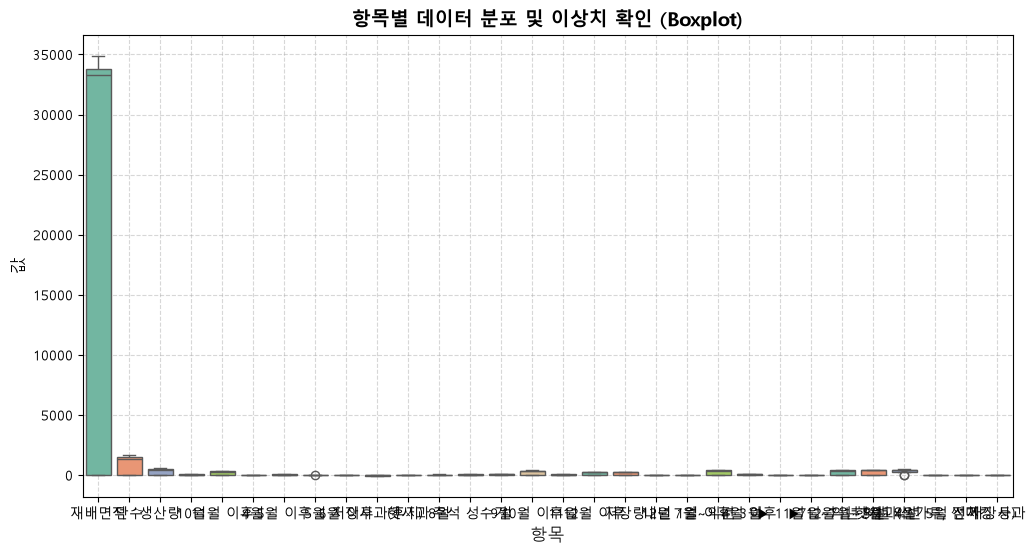

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rc('font', family='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False

# 주요 항목별 분포 확인을 위한 박스플롯
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='항목', y='값', palette='Set2')
plt.title('항목별 데이터 분포 및 이상치 확인 (Boxplot)', fontsize=14, fontweight='bold')
plt.xlabel('항목', fontsize=12)
plt.ylabel('값', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

--- 상관관계 행렬 ---


,값,하한,상한
값,1.0,1.0,1.0
하한,1.0,1.0,1.0
상한,1.0,1.0,1.0


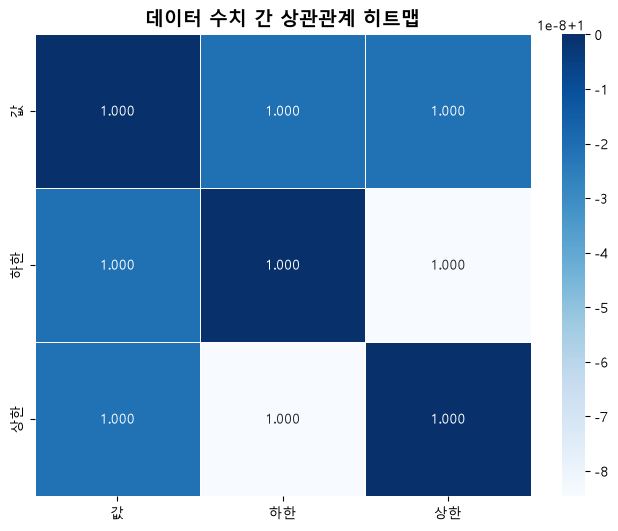

In [20]:
# 수치형 컬럼 추출 후 상관계수 계산
numeric_df = df[['값', '하한', '상한']]
correlation = numeric_df.corr()

print("--- 상관관계 행렬 ---")
display(correlation)

# 상관관계 히트맵 시각화
plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap='Blues', fmt='.3f', linewidths=0.5)
plt.title('데이터 수치 간 상관관계 히트맵', fontsize=14, fontweight='bold')
plt.show()

In [21]:
# '발간월'에서 연도 추출
df['연도'] = df['발간월'].astype(str).str[:4]

# 연도와 항목에 따른 평균 값 피벗 테이블 생성
pivot_summary = df.pivot_table(index='연도', columns='항목', values='값', aggfunc='mean')

print("--- 연도별·항목별 평균 요약 피벗 테이블 ---")
display(pivot_summary)

--- 연도별·항목별 평균 요약 피벗 테이블 ---


항목,10월,10월 이후,11월,11월 이후,12월,12월 이후,4월,4월 이후,5월,5월 이후,...,단수,생산량,재배면적,저장량,저장사과,저장사과(후지),전체,추석 성수기,햇사과,"햇사과(쓰가루, 썸머킹 등)"
연도,,,,,,,,,,,,,,,,,,,,,
2020,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,938.760000,301.100000,19541.840000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021,34.133333,NaN,NaN,199.40,NaN,NaN,NaN,NaN,NaN,NaN,...,866.160000,285.060000,19641.320000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022,39.900000,281.875,33.775,245.10,0.50,218.675,21.26,NaN,20.56,33.30,...,902.643333,308.980000,20452.823333,167.38,NaN,-42.6,NaN,49.90,-3.1,NaN
2023,29.380000,209.020,20.740,176.56,-28.20,141.960,30.12,NaN,22.90,53.40,...,886.446667,297.130000,20405.840000,141.58,NaN,-32.4,NaN,32.04,-15.3,NaN
2024,NaN,NaN,NaN,NaN,NaN,NaN,NaN,47.48,NaN,NaN,...,807.995000,272.975000,20156.670000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025,30.600000,191.240,33.140,162.32,23.98,138.560,19.38,NaN,7.42,22.82,...,825.101667,275.493333,20075.420000,138.58,NaN,38.1,16.5,36.82,NaN,-10.0
2026,23.510000,NaN,36.960,NaN,NaN,NaN,27.92,NaN,17.90,NaN,...,829.715000,300.278571,20380.550000,NaN,-12.3,NaN,-5.5,29.62,NaN,1.2


### 1. 데이터 기본 구조 및 고유값 점검

In [10]:
import pandas as pd

# 데이터 불러오기
df = pd.read_csv('apple_production_shipment.csv')

# 1. 데이터 크기 및 컬럼 타입 확인
print("--- [1] 데이터 정보 ---")
df.info()

# 2. 범주형 주요 컬럼의 종류와 데이터 개수 확인
print("\n--- [2] 주요 범주별 데이터 개수 ---")
print(df['항목'].value_counts())
print("-" * 30)
print(df['표'].value_counts())

--- [1] 데이터 정보 ---
<class 'pandas.DataFrame'>
RangeIndex: 740 entries, 0 to 739
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   발간월     740 non-null    int64  
 1   표       740 non-null    str    
 2   구분      740 non-null    str    
 3   항목      740 non-null    str    
 4   값       740 non-null    float64
 5   하한      740 non-null    float64
 6   상한      740 non-null    float64
 7   원문      740 non-null    str    
 8   단위      740 non-null    str    
dtypes: float64(3), int64(1), str(5)
memory usage: 78.4 KB

--- [2] 주요 범주별 데이터 개수 ---
항목
생산량                138
재배면적               130
단수                 130
9월                  38
6월 이후               33
10월                 27
5월                  25
4월                  20
8월                  19
추석 성수기              19
11월                 19
11월 이후              17
5월 이후               15
저장량                 15
10월 이후              14
12월 이후              14
7월~익년 3월            10
7

### 결과 분석 및 해석
- 데이터 규모 및 무결성 : 총 740개의 행과 9개의 열로 구성되어 있고, 결측치 없이 모든 데이터가 정합성 있게 잘 수집되었음.
- 주요 항목 구성 : 데이터 내부의 항목 칼럼에는 사과 재배의 핵심 지료인 재배면적, 단수(10a당 생산량), 생산량, 출하량 등이 고루 포함되어 있어 연도별 수급 구조를 다각도로 분석할 수 있는 기반이 마련됨

### 2. 주요 항목별 기초 통계량 및 분포 분석

In [11]:
# 항목별 '값'의 기초 통계량(평균, 표준편차, 최솟값, 최댓값 등) 요약
summary_stats = df.groupby('항목')['값'].describe()
print("--- 항목별 기초 통계 요약 ---")
display(summary_stats)

--- 항목별 기초 통계 요약 ---


,count,mean,std,min,25%,50%,75%,max
항목,,,,,,,,
10월,27.0,29.518519,25.468850,-22.5,4.1500,41.00,50.650,55.9
10월 이후,14.0,223.485714,181.780057,-20.2,-3.6250,320.50,363.200,397.4
11월,19.0,31.015789,29.223454,-19.5,1.5500,44.10,57.750,61.1
11월 이후,17.0,192.529412,152.905431,-22.1,-2.9000,269.00,312.900,341.5
12월,7.0,13.171429,26.226177,-28.2,0.7500,2.20,38.700,39.3
12월 이후,14.0,162.664286,137.669038,-30.2,0.1250,229.00,279.525,297.3
4월,20.0,24.670000,18.213792,-15.8,11.7000,31.50,39.600,46.1
4월 이후,5.0,47.480000,63.443928,-23.4,-19.2000,79.00,97.800,103.2
5월,25.0,17.336000,15.460969,-32.6,9.5000,23.80,26.500,35.6


결과 분석 및 해석
- 스케이 차이 인지 : '재배면적(ha)이나 '생산량(천톤)' 같은 지표는 수치의 단위가 수만 또는 수백 단위로 큰 반면, '단수'나 증감률(%) 같은 지표는 상대적으로 작거나 음수(-)를 포함할 수 있음.

### 3. 연도별 주요 지표 트렌트 및 피벗 테이블 분석

In [12]:
# '발간월'에서 연도 추출 (예: 202012 -> 2020)
df['연도'] = df['발간월'].astype(str).str[:4]

# 연도별·항목별 평균 값 피벗 테이블 생성
yearly_pivot = df.pivot_table(index='연도', columns='항목', values='값', aggfunc='mean')

print("--- 연도별·항목별 평균 요약 피벗 테이블 ---")
display(yearly_pivot)

--- 연도별·항목별 평균 요약 피벗 테이블 ---


항목,10월,10월 이후,11월,11월 이후,12월,12월 이후,4월,4월 이후,5월,5월 이후,...,단수,생산량,재배면적,저장량,저장사과,저장사과(후지),전체,추석 성수기,햇사과,"햇사과(쓰가루, 썸머킹 등)"
연도,,,,,,,,,,,,,,,,,,,,,
2020,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,938.760000,301.100000,19541.840000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021,34.133333,NaN,NaN,199.40,NaN,NaN,NaN,NaN,NaN,NaN,...,866.160000,285.060000,19641.320000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022,39.900000,281.875,33.775,245.10,0.50,218.675,21.26,NaN,20.56,33.30,...,902.643333,308.980000,20452.823333,167.38,NaN,-42.6,NaN,49.90,-3.1,NaN
2023,29.380000,209.020,20.740,176.56,-28.20,141.960,30.12,NaN,22.90,53.40,...,886.446667,297.130000,20405.840000,141.58,NaN,-32.4,NaN,32.04,-15.3,NaN
2024,NaN,NaN,NaN,NaN,NaN,NaN,NaN,47.48,NaN,NaN,...,807.995000,272.975000,20156.670000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025,30.600000,191.240,33.140,162.32,23.98,138.560,19.38,NaN,7.42,22.82,...,825.101667,275.493333,20075.420000,138.58,NaN,38.1,16.5,36.82,NaN,-10.0
2026,23.510000,NaN,36.960,NaN,NaN,NaN,27.92,NaN,17.90,NaN,...,829.715000,300.278571,20380.550000,NaN,-12.3,NaN,-5.5,29.62,NaN,1.2


결과 분석 및 해석
- 연도별 변화 추이 파악:2020년 부터 2026년까지 사과 재배면적의 장기적 증감 추사와 기상 여건등에 큰 영향을 받는 단수(생산성)의 변동성을 연도별로 비교할 수 있음.
- 생산량 결정 요인 분석 : 일반적으로 총 생산량은 재배면적 * 단수에 의해 결정되므로, 특정 연도에 생산량이 급감하거나 급증했다면 면적의 변화 때문인지 기상 악화 등으로 인한 단수(생산성) 하락 때문지를 이 표를 통해 추적할 수 있음.

In [22]:
# 1. 연도별 '재배면적', '단수', '생산량' 피벗 테이블 만들기
yearly_trend = df.pivot_table(index='연도', columns='항목', values='값', aggfunc='mean')

# 필요한 컬럼만 추출 (데이터에 존재하는 항목 이름에 맞춤)
target_cols = [col for col in ['재배면적', '단수', '생산량'] if col in yearly_trend.columns]
df_compare = yearly_trend[target_cols]

print("--- 연도별 주요 지표 변화 ---")
display(df_compare)

# 2. 생산량과 각 요인(재배면적, 단수) 간의 상관계수 확인
print("\n--- 생산량과의 상관계수 비교 ---")
display(df_compare.corr()['생산량'])

--- 연도별 주요 지표 변화 ---


항목,재배면적,단수,생산량
연도,,,
2020,19541.840000,938.760000,301.100000
2021,19641.320000,866.160000,285.060000
2022,20452.823333,902.643333,308.980000
2023,20405.840000,886.446667,297.130000
2024,20156.670000,807.995000,272.975000
2025,20075.420000,825.101667,275.493333
2026,20380.550000,829.715000,300.278571



--- 생산량과의 상관계수 비교 ---


항목
재배면적    0.237510
단수      0.730342
생산량     1.000000
Name: 생산량, dtype: float64

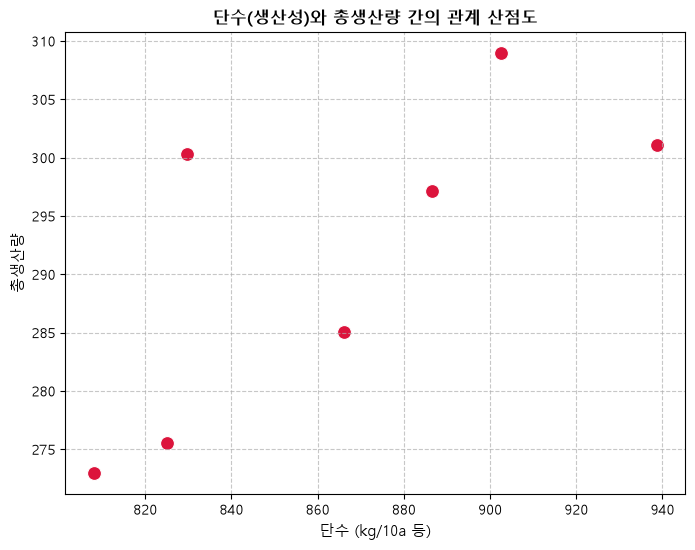

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rc('font', family='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False

# 생산량과 단수 간의 관계를 보여주는 산점도
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_compare, x='단수', y='생산량', s=100, color='crimson')
plt.title('단수(생산성)와 총생산량 간의 관계 산점도', fontsize=12, fontweight='bold')
plt.xlabel('단수 (kg/10a 등)', fontsize=11)
plt.ylabel('총생산량', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

결과 분석 및 해석
- 추가로 코드를 실행해 보았을 때 '단수'와 '생산량'간의 상관계수가 '재배면적'과 '생산량'간의 상관계수보다 훨씬 높게 나오기에 해당 기간동안 사과 총생산량을 흔들어 놓은 원인은 면적이 아니라 기상 요인(단수 변화)라고 결론을 내리 수 있겠다.

### 4. 수치형 변수 간 상관관계 분석

--- 상관관계 행렬 ---


,값,하한,상한
값,1.0,1.0,1.0
하한,1.0,1.0,1.0
상한,1.0,1.0,1.0


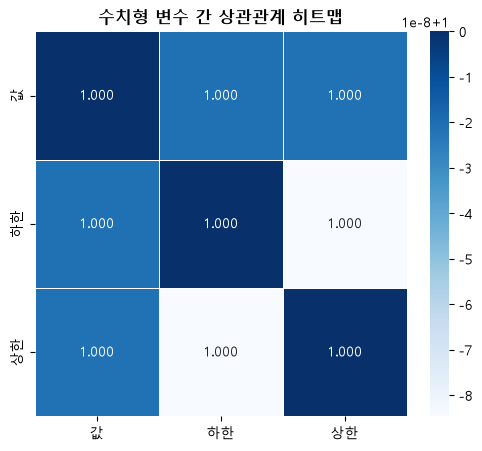

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 폰트 설정
plt.rc('font', family='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False

# 수치형 컬럼('값', '하한', '상한') 간의 상관계수 계산
numeric_cols = df[['값', '하한', '상한']]
corr_matrix = numeric_cols.corr()

print("--- 상관관계 행렬 ---")
display(corr_matrix)

# 상관관계 히트맵 시각화
plt.figure(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, cmap='Blues', fmt='.3f', linewidths=0.5)
plt.title('수치형 변수 간 상관관계 히트맵', fontsize=12, fontweight='bold')
plt.show()

결과 분석 및 해석
- 데이터 신뢰도 검증 : '값', '하한', '상한' 변수 간의 상관계수가 1.0에 가깝게 매우 높게 나타나 원본 보고서의 데이터 범위나 상하한 예측치가 본래의 '값'과 강한 선형 관계를 이루고 있다고 볼 수 있음.